![img](https://github.com/JuliaLang/julia/raw/master/doc/src/assets/logo.svg)![img](https://avatars.githubusercontent.com/u/7346142?s=200&v=4)

# 1. Setup

The setup is the same as in the GPU introduction, which explains it. The cells below activate the project environment, install and load the packages, and select the backend; set `DEV` in the last cell to match your hardware.

In [1]:
using Pkg
Pkg.activate(@__DIR__)

  Activating project at `c:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions`


In [2]:
Pkg.add(["BenchmarkTools", "KernelAbstractions", "CUDA", "AMDGPU", "Metal", "Plots"])

   Resolving package versions...
     Project No packages added to or removed from `C:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\Project.toml`
    Manifest No packages added to or removed from `C:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\Manifest.toml`


In [3]:
using BenchmarkTools, LinearAlgebra, KernelAbstractions, Plots

In [4]:
Pkg.status()

Status `C:\Users\evely\OneDrive\Documents\CSE_MIT\julia-hpc-tutorial-sc26\02-Parallel-Programming\KernelAbstractions\Project.toml`
⌃ [21141c5a] AMDGPU v2.10.0
  [6e4b80f9] BenchmarkTools v1.8.0
  [052768ef] CUDA v6.5.0
  [7073ff75] IJulia v1.34.4
  [63c18a36] KernelAbstractions v0.10.4
  [dde4c033] Metal v1.12.0
  [91a5bcdd] Plots v1.41.7
  [92933f4c] ProgressMeter v1.13.0
  [37e2e46d] LinearAlgebra v1.12.0
Info Packages marked with ⌃ have new versions available and may be upgradable.


## 1.1. Selecting a backend

In [5]:
# Pick your hardware: :NVIDIA, :AMD, :Metal, or :CPU
DEV = :NVIDIA

if DEV == :NVIDIA
    using CUDA
    ArrayKA = CUDA.CuArray
    Backend = CUDA.CUDABackend()
elseif DEV == :AMD
    using AMDGPU
    ArrayKA = AMDGPU.ROCArray
    Backend = AMDGPU.ROCBackend()
elseif DEV == :Metal
    using Metal
    ArrayKA = Metal.MtlArray
    Backend = Metal.MetalBackend()
elseif DEV == :CPU
    ArrayKA = Array
    Backend = CPU()
else
    error("Unknown DEV = $DEV. Use :NVIDIA, :AMD, :Metal, or :CPU.")
end

CUDABackend(false, false, false)

# 2. Transpose and matrix multiplication

We will examine a transpose kernel and you will write a matmul (matrix-multiplication or GEMM) kernel.

## 2.1. Transpose

We use `Float32` throughout. Single precision is much faster than `Float64` on GPUs, by a factor of 32 to 64 on consumer cards, and Apple GPUs do not support `Float64` at all.

In [6]:
matrix_size = 1024
A = rand(Float32, matrix_size, matrix_size)
B = rand(Float32, matrix_size, matrix_size)
C = zeros(Float32, matrix_size, matrix_size)

A

1024×1024 Matrix{Float32}:
 0.0541471  0.904754   0.16987    …  0.231221    0.46002   0.0796956
 0.321646   0.882234   0.953808      0.965871    0.438139  0.4936
 0.815376   0.677445   0.892058      0.0757049   0.591902  0.29945
 0.409079   0.61354    0.150908      0.30932     0.573953  0.236124
 0.616788   0.229178   0.954189      0.386446    0.523268  0.769823
 0.791797   0.454075   0.624462   …  0.224996    0.179292  0.60904
 0.710335   0.933154   0.26638       0.169183    0.136245  0.32978
 0.698507   0.0293009  0.72939       0.00286329  0.594955  0.506974
 0.859141   0.853739   0.549159      0.388417    0.671623  0.296195
 0.1489     0.509327   0.892694      0.861371    0.425357  0.0307247
 ⋮                                ⋱                        
 0.408379   0.11411    0.940801   …  0.58881     0.90466   0.450334
 0.959038   0.446588   0.68391       0.78182     0.599159  0.539502
 0.48418    0.512186   0.0413982     0.310712    0.216931  0.478874
 0.790569   0.23554    0.302898 

### 2.1.1. On the CPU

The transpose `AT` of `A` satisfies `AT[j, i] = A[i, j]`.

In [7]:
AT = zeros(Float32, matrix_size, matrix_size)

function Transpose!(AT, A)
    for j in 1:size(A, 2)
        for i in 1:size(A, 1)
            AT[j, i] = A[i, j]
        end
    end
end

Transpose!(AT, A)
AT == transpose(A)

true

`permutedims!(dest, src, (2, 1))` writes the transpose into an existing array. The permutation `(2, 1)` swaps the two dimensions. It is the built-in transpose, as `*` is the built-in product. `transpose(A)` itself does not copy; it only swaps the indexing.

In [8]:
YT = zeros(Float32, matrix_size, matrix_size)
permutedims!(YT, A, (2, 1))
YT == transpose(A)

true

### 2.1.2. On the device

Copy `A` to the device, as for the vectors in the GPU introduction:

In [9]:
DA = allocate(Backend, Float32, matrix_size, matrix_size)
copyto!(DA, A)

DA

1024×1024 CuArray{Float32, 2, CUDACore.DeviceMemory}:
 0.0541471  0.904754   0.16987    …  0.231221    0.46002   0.0796956
 0.321646   0.882234   0.953808      0.965871    0.438139  0.4936
 0.815376   0.677445   0.892058      0.0757049   0.591902  0.29945
 0.409079   0.61354    0.150908      0.30932     0.573953  0.236124
 0.616788   0.229178   0.954189      0.386446    0.523268  0.769823
 0.791797   0.454075   0.624462   …  0.224996    0.179292  0.60904
 0.710335   0.933154   0.26638       0.169183    0.136245  0.32978
 0.698507   0.0293009  0.72939       0.00286329  0.594955  0.506974
 0.859141   0.853739   0.549159      0.388417    0.671623  0.296195
 0.1489     0.509327   0.892694      0.861371    0.425357  0.0307247
 ⋮                                ⋱                        
 0.408379   0.11411    0.940801   …  0.58881     0.90466   0.450334
 0.959038   0.446588   0.68391       0.78182     0.599159  0.539502
 0.48418    0.512186   0.0413982     0.310712    0.216931  0.478874
 0.79

In [10]:
DAt = KernelAbstractions.zeros(Backend, Float32, matrix_size, matrix_size)
permutedims!(DAt, DA, (2, 1))
KernelAbstractions.synchronize(Backend)

Array(DAt) == transpose(A)

true

### 2.1.3. Naive transpose kernel

For matrices, `@index(Global, NTuple)` returns a pair `(i, j)` instead of a single index. Without `NTuple`, the global index stays linear rather than a row and column. With `ndrange = size(A)`, KernelAbstractions launches one work item per matrix element; a 2D workgroup shape unpacks the linear work-item range into `(i, j)`. That 2D view is a convenience for writing matrix indices—the hardware still uses linear thread ids and linear memory.

Each work item performs one assignment, as in `Transpose!`: obtain `(i, j)` and copy one value. Each output location `AT[j, i]` has a single writer, and the kernel does not use `@localmem`, so there is no shared-memory race. (Global races like the sum in the GPU introduction come from many work items updating the same address; that does not happen here.)


In [11]:
@kernel function transpose_kernel!(AT, @Const(A))
    i, j = @index(Global, NTuple)
    @inbounds AT[j, i] = A[i, j]
end

transpose_kernel! (generic function with 4 methods)

We launch 1024 × 1024 work items (`ndrange=size(DA)`) in workgroups of 32 × 32 = 1024, the maximum workgroup size on current NVIDIA and AMD GPUs. Since 1024 is a multiple of 32, every workgroup is full and no bounds check is needed.

In [12]:
DAT = KernelAbstractions.zeros(Backend, Float32, matrix_size, matrix_size)

naive_transpose! = transpose_kernel!(Backend, (32, 32))
naive_transpose!(DAT, DA, ndrange=size(DA))
KernelAbstractions.synchronize(Backend)

Array(DAT) == transpose(A)

true

### 2.1.4. Timing

We now compare CPU and device `permutedims!` at `matrix_size` and over a range of `N`. Device timings wait until the call has finished, as in the GPU introduction.

In [13]:
XT = zeros(Float32, matrix_size, matrix_size)
YT = zeros(Float32, matrix_size, matrix_size)

@benchmark Transpose!($XT, $A)

BenchmarkTools.Trial: 857 samples with 1 evaluation per sample.
 Range (min … max):  5.714 ms …   8.353 ms  ┊ GC (min … max): 0.00% … 0.00%
 Time  (median):     5.784 ms               ┊ GC (median):    0.00%
 Time  (mean ± σ):   5.834 ms ± 175.407 μs  ┊ GC (mean ± σ):  0.00% ± 0.00%

   █▂▁▃▁▁                                                      
  ███████▇▆▅▄▄▄▃▂▄▄▄▄▃▃▃▃▃▃▃▃▃▃▂▃▂▂▂▂▂▂▂▂▁▁▁▂▂▂▁▁▁▁▂▂▁▂▁▂▁▂▂▂ ▃
  5.71 ms         Histogram: frequency by time        6.41 ms <

 Memory estimate: 0 bytes, allocs estimate: 0.

In [14]:
@benchmark permutedims!($YT, $A, (2, 1))

BenchmarkTools.Trial: 1108 samples with 1 evaluation per sample.
 Range (min … max):  4.318 ms …   7.955 ms  ┊ GC (min … max): 0.00% … 0.00%
 Time  (median):     4.419 ms               ┊ GC (median):    0.00%
 Time  (mean ± σ):   4.512 ms ± 293.215 μs  ┊ GC (mean ± σ):  0.00% ± 0.00%

  █▇▇▆▆▆▅▄▄▃▃▄▁▂▃▃▂▂▂   ▁                                     ▁
  ████████████████████▇▅█▇▆▇▇▄▆▆▅▇▆▆▆▆▄▇▆▁▆▅▅▅▆▅▄▅▄▅▆▅▆▁▅▄▆▄▄ █
  4.32 ms      Histogram: log(frequency) by time      5.49 ms <

 Memory estimate: 0 bytes, allocs estimate: 0.

One timing at a single `N` hides how the cost grows. The next cell defines `sizes` and `tlabel`, times CPU and device `permutedims!`, `Transpose!`, and `transpose_kernel!`, and builds `plt_transpose`.

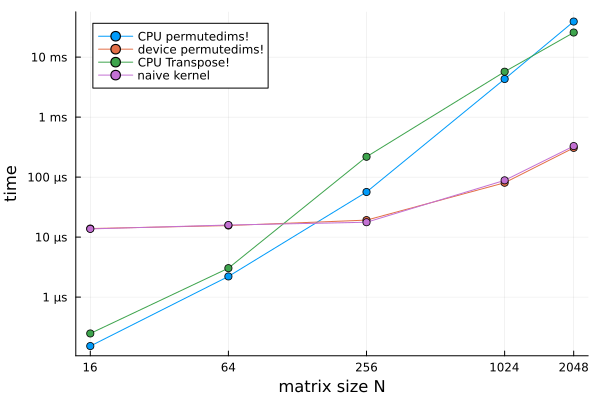

In [15]:
sizes = [16, 64, 256, 1024, 2048]
t_cpu_perm = Float64[]
t_dev_perm = Float64[]
t_cpu_transpose, t_naive_transpose = Float64[], Float64[]
for n in sizes
    X = rand(Float32, n, n)
    XT = similar(X)
    XT_loop = zeros(Float32, n, n)
    push!(t_cpu_perm, @belapsed permutedims!($XT, $X, (2, 1)))
    push!(t_cpu_transpose, @belapsed Transpose!($XT_loop, $X))
    DX = allocate(Backend, Float32, n, n)
    copyto!(DX, X)
    DXT = KernelAbstractions.zeros(Backend, Float32, n, n)
    push!(t_dev_perm, @belapsed begin
        permutedims!($DXT, $DX, (2, 1))
        KernelAbstractions.synchronize($Backend)
    end)
    w = min(32, n)
    naive! = transpose_kernel!(Backend, (w, w))
    DXT_naive = KernelAbstractions.zeros(Backend, Float32, n, n)
    push!(t_naive_transpose, @belapsed begin
        $naive!($DXT_naive, $DX; ndrange = ($n, $n))
        KernelAbstractions.synchronize($Backend)
    end)
end

tlabel(v) = begin
    x, u = v < 1e-6 ? (v * 1e9, "ns") : v < 1e-3 ? (v * 1e6, "µs") : v < 1 ? (v * 1e3, "ms") : (v, "s")
    r = round(x; sigdigits = 2)
    string(isinteger(r) ? Int(r) : r, " ", u)
end

plt_transpose = Plots.plot(sizes, [t_cpu_perm t_dev_perm t_cpu_transpose t_naive_transpose];
    label = ["CPU permutedims!" "device permutedims!" "CPU Transpose!" "naive kernel"],
    xlabel = "matrix size N", ylabel = "time",
    xscale = :log2, yscale = :log10,
    xticks = (sizes, string.(sizes)),
    yformatter = tlabel, marker = :circle, legend = :topleft)
plt_transpose

<div style="border-left: 4px solid #868e96; background: rgba(134, 142, 150, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Question (2.1.4).** The cell above builds `plt_transpose` with CPU and device `permutedims!`, CPU `Transpose!`, and the naive transpose kernel.

1. For small `N`, why can device `permutedims!` sit on a flat floor where the time barely changes when you increase `N`? What fixed cost dominates before moving `N²` elements matters?
2. Why can CPU `permutedims!` beat the device call for small matrices, and why does the device library call usually pull ahead once `N` is large enough? What has to be amortized for the device to win?
3. Will CPU and device `permutedims!` cross over at the same `N` on every machine or GPU? What varies between students’ plots?

</div>

<div style="border-left: 4px solid #868e96; background: rgba(134, 142, 150, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Question (2.1.3).** The kernel keeps the input in `@Const(A)` and writes a separate `AT`. Suppose instead every work item executed `A[j, i] = A[i, j]` on **one** device array `DA` (same buffer for input and output, no `@Const`).

1. For `i ≠ j`, work item `(i, j)` reads `A[i, j]` and writes `A[j, i]`. Which other work item also reads or writes those two locations?
2. Can `(i, j)` still read the original `A[i, j]` if `(j, i)` runs first? How is that related to the global race in the GPU introduction?
3. Why does the version above use `DAT` and `@Const(DA)`?

</div>

## 2.2. Matrix multiplication

### 2.2.1. On the CPU

Dense matrix multiplication is the core of most dense linear algebra and the standard benchmark for floating-point throughput.

The textbook triple loop is given below; you will port its inner product to the device in Exercise 4.

In [16]:
function MatrixMultiplication!(C, A, B)
    for i in 1:size(C, 1)
        for j in 1:size(C, 2)
            C[i, j] = 0
            for k in 1:size(A, 2)
                C[i, j] += A[i, k] * B[k, j]
            end
        end
    end
end

MatrixMultiplication! (generic function with 1 method)

<div style="border-left: 4px solid #5c7cfa; background: rgba(92, 124, 250, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

## Exercise 2: CPU matrix multiplication

Run the triple loop on `A` and `B` and compare the result with Julia's `*`.

Write one line of code at the `# TODO`. A solution is in `proposed-solution/exercise_2_cpu_matmul.ipynb`.

</div>

In [17]:
# TODO 1: run the MatrixMultiplication! on C, A, and B

isapprox(C, A * B)

false

### 2.2.2. On the device

Copy `B` and allocate `DC`. Matrix multiplication on device arrays calls the vendor library (cuBLAS under CUDA, rocBLAS under ROCm, Metal on Apple; OpenBLAS when `DEV = :CPU`), unlike elementwise `+`, which launches a generated kernel.

<div style="border-left: 4px solid #5c7cfa; background: rgba(92, 124, 250, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

## Exercise 3: Device library matrix multiplication

Copy `B` to the device, allocate `DC`, and multiply with `DA * DB`. Check against the CPU answer.

Write one line of code at each `# TODO`. A solution is in `proposed-solution/exercise_3_device_matmul.ipynb`.

</div>

In [18]:
# TODO 1: allocate DB and DA on the device (Float32, matrix_size × matrix_size)

# TODO 2: copy host matrix B and A onto DB and DA

# TODO 3: allocate DC as zeros on the device (same shape as DB)


In [19]:
# TODO 4: store DA * DB in DC

isapprox(Array(DC), A * B)

UndefVarError: UndefVarError: `DC` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

### 2.2.3. Naive matrix multiplication

These kernels do not call the library. Each work item writes one element. Transpose was the worked example in section 2.1; here you write the matrix multiplication kernel in the same style.

<div style="border-left: 4px solid #5c7cfa; background: rgba(92, 124, 250, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

## Exercise 4: Naive matrix multiplication

Write `MatrixMultiplication_kernel!` with one work item per element of `C`. Work item `(row, col)` computes the dot product of row `row` of `A` and column `col` of `B`. This is the innermost loop of the CPU `MatrixMultiplication!`; the two outer loops are replaced by the work items.

Write one line at each `# TODO`. The second cell clears `DC`; synchronize and the correctness check are already filled in. It should print `true`. A solution is in `proposed-solution/exercise_4_naive_matmul.ipynb`.

</div>

In [20]:
@kernel function MatrixMultiplication_kernel!(C, @Const(A), @Const(B))
    # TODO 1: this work item's (row, col) from @index(Global, NTuple)

    acc = zero(eltype(C))

    for k in 1:size(A, 2)
        # TODO 2: one term of the dot product added to acc
    end

    # TODO 3: write acc to C[row, col]

end

MatrixMultiplication_kernel! (generic function with 4 methods)

In [21]:
fill!(DC, 0)

# TODO 4: build kernel! with 32 × 32 workgroups

# TODO 5: launch kernel! on DC, DA, and DB

KernelAbstractions.synchronize(Backend)

isapprox(Array(DC), A * B)

UndefVarError: UndefVarError: `DC` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

### 2.2.4. Timing

We now compare CPU and device `*` at `matrix_size` and over `sizes`. Device timings wait until the call has finished, as in the GPU introduction.

In [22]:
@benchmark MatrixMultiplication!($C, $A, $B)

BenchmarkTools.Trial: 2 samples with 1 evaluation per sample.
 Range (min … max):  4.697 s …   4.721 s  ┊ GC (min … max): 0.00% … 0.00%
 Time  (median):     4.709 s              ┊ GC (median):    0.00%
 Time  (mean ± σ):   4.709 s ± 16.991 ms  ┊ GC (mean ± σ):  0.00% ± 0.00%

  █                                                       █  
  █▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁█ ▁
  4.7 s          Histogram: frequency by time        4.72 s <

 Memory estimate: 0 bytes, allocs estimate: 0.

In [23]:
@benchmark A * B

BenchmarkTools.Trial: 585 samples with 1 evaluation per sample.
 Range (min … max):  5.664 ms … 96.905 ms  ┊ GC (min … max): 0.00% …  0.00%
 Time  (median):     7.675 ms              ┊ GC (median):    0.00%
 Time  (mean ± σ):   8.547 ms ±  5.021 ms  ┊ GC (mean ± σ):  6.42% ± 12.10%

   █▄  ▅▄▅▆▆▃▂  ▅▂                                            
  ▅████████████▇████▇▆▄▅▇▅▄▅▄▅▆▄▃▄▄▆▄▄▄▅▅▂▃▃▁▂▃▂▁▃▃▂▃▁▂▃▁▁▁▂ ▄
  5.66 ms        Histogram: frequency by time        15.4 ms <

 Memory estimate: 4.00 MiB, allocs estimate: 3.

We compare your kernel with the library's `DA * DB`. Both benchmarks include `synchronize`, so they measure the time until the result is available:

In [24]:
@benchmark begin
    DA * DB
    KernelAbstractions.synchronize(Backend)
end

UndefVarError: UndefVarError: `DB` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [25]:
@benchmark begin
    kernel!(DC, DA, DB, ndrange=size(DC))
    KernelAbstractions.synchronize(Backend)
end

UndefVarError: UndefVarError: `DC` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

One timing at a single `N` hides how the cost grows. OpenBLAS, the library `*` dispatches to, is much faster than the triple loop: it blocks for the cache hierarchy, vectorizes with SIMD instructions, and uses all cores. The next cell times CPU and device `*`, the triple loop, and the naive matmul kernel over `sizes`, and builds `plt_matmul`.


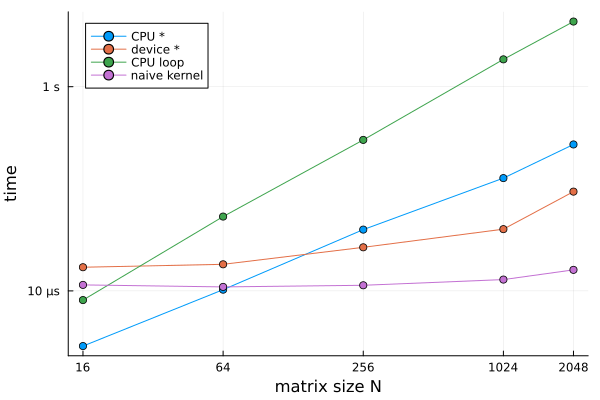

In [26]:
t_cpu_mul = Float64[]
t_dev_mul = Float64[]
t_cpu_loop, t_dev_naive = Float64[], Float64[]
for n in sizes
    X, Y = rand(Float32, n, n), rand(Float32, n, n)
    Z = zeros(Float32, n, n)
    push!(t_cpu_mul, @belapsed $X * $Y)
    push!(t_cpu_loop, @belapsed MatrixMultiplication!($Z, $X, $Y))
    DX = allocate(Backend, Float32, n, n)
    copyto!(DX, X)
    DY = allocate(Backend, Float32, n, n)
    copyto!(DY, Y)
    push!(t_dev_mul, @belapsed begin
        $DX * $DY
        KernelAbstractions.synchronize($Backend)
    end)
    DZ = KernelAbstractions.zeros(Backend, Float32, n, n)
    w = min(32, n)
    k! = MatrixMultiplication_kernel!(Backend, (w, w))
    push!(t_dev_naive, @belapsed begin
        $k!($DZ, $DX, $DY; ndrange = ($n, $n))
        KernelAbstractions.synchronize($Backend)
    end)
end

plt_matmul = Plots.plot(sizes, [t_cpu_mul t_dev_mul t_cpu_loop t_dev_naive];
    label = ["CPU *" "device *" "CPU loop" "naive kernel"],
    xlabel = "matrix size N", ylabel = "time",
    xscale = :log2, yscale = :log10,
    xticks = (sizes, string.(sizes)),
    yformatter = tlabel, marker = :circle, legend = :topleft)
plt_matmul


<div style="border-left: 4px solid #868e96; background: rgba(134, 142, 150, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Question (2.2.4).** The cell above builds `plt_matmul` over several matrix sizes.

1. For small `N`, why can the device `*` and naive kernel curves sit on a flat floor that barely changes when you increase `N`? What fixed cost dominates before the multiply itself matters?
2. As `N` grows, why do those curves rise above the floor? How does the work of matrix multiplication scale with `N`, and when does that work dominate the launch cost?
3. On a GPU backend, why is vendor `*` (`DA * DB`) usually much faster than the naive kernel at large `N`? If you set `DEV = :CPU`, what do the two `*` curves both measure?

</div>

## 2.4. Tiled kernels

### 2.4.1. Shared memory

The library is much faster than one work item per output element. In the naive matrix multiplication kernel every work item reads a full row of `DA` and a full column of `DB` from global memory, although neighboring work items need largely the same values. Libraries tile the computation instead: each workgroup loads blocks of `DA` and `DB` into shared memory once and reuses them. On NVIDIA GPUs they also use tensor cores. Shared memory (`@localmem`) is a scratchpad private to one workgroup. A work item can read a value stored there by another work item of the same workgroup. The tiled kernels keep a tile in that scratchpad: the transpose so the write is coalesced, and the product so each loaded value is reused.

<div style="border-left: 4px solid #e03131; background: rgba(224, 49, 49, 0.08); padding: 0.6em 1.2em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Warning.** When different work items in one workgroup write and then read the same `@localmem` tile, you get a **race condition** like the global sum in the GPU introduction: the result depends on which work items run first. A work item can read a shared cell before a neighbor has stored it, or overwrite a tile while others still read it. Put a [`@synchronize()`](https://juliagpu.github.io/KernelAbstractions.jl/stable/api/#KernelAbstractions.@synchronize) between those phases so every load finishes before any read (see the [KernelAbstractions manual](https://juliagpu.github.io/KernelAbstractions.jl/stable/kernels/#Local-memory,-synchronization,-and-private-memory)). Use `@synchronize()` again before reloading the tile in multi-step kernels (Exercise 5). `@synchronize()` orders work items inside one workgroup only; `KernelAbstractions.synchronize(Backend)` makes the host wait for the device.

</div>

Each workgroup of `TILE_DIM × TILE_DIM` work items owns one tile. With many workgroups, each work item also needs to know which tile it belongs to:

| Construct | Meaning |
|---|---|
| `@index(Group, NTuple)` | index of the workgroup, `(gi, gj)` |
| `@index(Local, NTuple)` | index within the workgroup, `(i, j)` |

Work item `(i, j)` of workgroup `(gi, gj)` handles row `(gi - 1) * TILE_DIM + i` and column `(gj - 1) * TILE_DIM + j`, the same pair `@index(Global, NTuple)` would return.


### 2.4.2. Transpose

In the **load** phase, work item `(i, j)` reads global `A` and **writes shared `tile[i, j]`** (neighboring work items hit neighboring addresses in `A`, so the load is coalesced). That is only half of the tile: work item `(j, i)` **writes `tile[j, i]`**, a different shared cell, from its own global read. 

After **`@synchronize()`**, the **store** phase swaps roles in shared memory: `(i, j)` **reads `tile[j, i]`**—which only `(j, i)` wrote—and writes that value to global `AT` at the transposed tile position. Symmetrically, `(j, i)` reads `tile[i, j]`. Without the barrier, `(i, j)` can read `tile[j, i]` before `(j, i)` has finished storing it. 


In [27]:
const TILE_DIM = 16

@kernel unsafe_indices=true function transpose_tiled_kernel!(AT, @Const(A))
    gi, gj = @index(Group, NTuple)
    i, j = @index(Local, NTuple)
    N = @uniform @groupsize()[1]

    # (i,j) writes tile[i,j] then reads tile[j,i] (written by work item (j,i)); +1 row reduces bank conflicts on that read
    tile = @localmem eltype(A) (N + 1, N)

    I = (gi - 1) * N + i
    J = (gj - 1) * N + j
    @inbounds tile[i, j] = A[I, J]   # load phase: each work item fills one slot of tile

    @synchronize()   # wait until every tile[i,j] and tile[j,i] is written

    I = (gj - 1) * N + i
    J = (gi - 1) * N + j
    @inbounds AT[I, J] = tile[j, i]   # store phase: (i,j) reads the slot (j,i) filled
end

transpose_tiled_kernel! (generic function with 4 methods)

In [28]:
fill!(DAT, 0)

tiled_transpose! = transpose_tiled_kernel!(Backend, (TILE_DIM, TILE_DIM))
tiled_transpose!(DAT, DA, ndrange=size(DA))
KernelAbstractions.synchronize(Backend)

Array(DAT) == transpose(A)

true

The tiled transpose is added to `plt_transpose`. The library, `Transpose!`, and `transpose_kernel!` curves from section 2.1.4 are already on that figure.

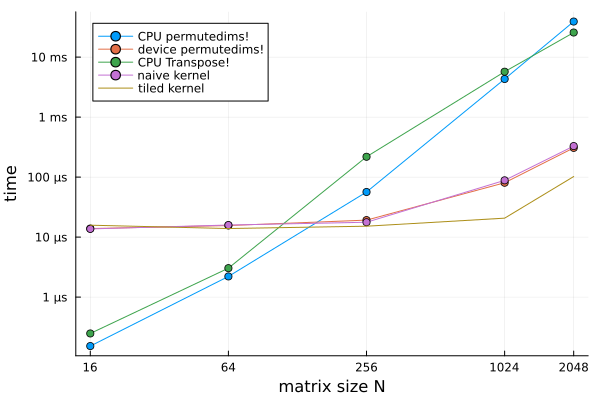

In [29]:
t_tiled_transpose = Float64[]
for n in sizes
    X = rand(Float32, n, n)
    DX = copyto!(allocate(Backend, Float32, n, n), X)
    DXT = KernelAbstractions.zeros(Backend, Float32, n, n)
    kt! = transpose_tiled_kernel!(Backend, (TILE_DIM, TILE_DIM))
    push!(t_tiled_transpose, @belapsed begin
        $kt!($DXT, $DX; ndrange = ($n, $n))
        KernelAbstractions.synchronize($Backend)
    end)
end

Plots.plot!(plt_transpose, sizes, t_tiled_transpose; label = "tiled kernel")
plt_transpose

<div style="border-left: 4px solid #868e96; background: rgba(134, 142, 150, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Question (2.4.2).** Section 2.1.4 plots CPU and device `permutedims!`, CPU `Transpose!`, the naive transpose kernel, and (after the cell above) the tiled transpose kernel.

1. For small `N`, why do the naive and tiled **device** kernels often take **similar** times that barely change when you increase `N`? What fixed cost dominates before the matrix is large enough for the transpose itself to matter?
2. As `N` grows, when do the device kernels typically become faster than CPU `Transpose!`? When does the tiled kernel become faster than the naive device kernel, and **why** does tiling help more as the matrix gets larger?
3. Why can device `permutedims!` lose to the CPU version for small `N`? When does the device library call usually pull ahead, and **why** can a hand-written tiled kernel eventually compete with or beat the vendor library at large `N`?

</div>

### 2.4.3. Matrix multiplication

![Tiles of a matrix product. One output tile is the sum, over the inner index, of a tile of each factor.](img/matmul.svg)

Each workgroup owns one tile of `C`. The workgroup walks the inner dimension in steps `t`: load matching tiles of `A` and `B` into shared `tileA` and `tileB`, `@synchronize`, update each work item's running sum from those tiles, then `@synchronize` again before the next pair overwrites shared memory. Exercise 5 implements that loop.


<div style="border-left: 4px solid #5c7cfa; background: rgba(92, 124, 250, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

## Exercise 5: Tiled matrix multiplication

Write `tiled_matmul_kernel!` with shared tiles `tileA` and `tileB`. The skeleton already computes `row`, `col`, and the loop over `t`. Write one line at each `# TODO`. The second cell clears `DC`; synchronize and the correctness check are already filled in. A solution is in `proposed-solution/exercise_5_tiled_matmul.ipynb`.

</div>


In [30]:
@kernel function tiled_matmul_kernel!(C, @Const(A), @Const(B))
    gi, gj = @index(Group, NTuple)
    i, j = @index(Local, NTuple)

    # TODO 1: shared tiles tileA and tileB (TILE_DIM × TILE_DIM each)

    row = (gi - 1) * TILE_DIM + i
    col = (gj - 1) * TILE_DIM + j
    acc = zero(eltype(C))

    for t in 0:(size(A, 2) ÷ TILE_DIM - 1)
        # TODO 2: load your work item's elements into tileA and tileB

        # TODO 3: @synchronize() after loads

        for k in 1:TILE_DIM
            # TODO 4: multiply-add using tileA and tileB
        end

        # TODO 5: @synchronize() before the next tile step

    end

    # TODO 6: write acc to C[row, col]

end

tiled_matmul_kernel! (generic function with 4 methods)

In [31]:
fill!(DC, 0)

# TODO 7: build tiled! with TILE_DIM × TILE_DIM workgroups

# TODO 8: launch tiled! on DC, DA, and DB

KernelAbstractions.synchronize(Backend)

isapprox(Array(DC), A * B)

UndefVarError: UndefVarError: `DC` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

We time your tiled kernel for comparison with the naive kernel and the library in section 2.2:

In [32]:
@benchmark begin
    tiled!(DC, DA, DB, ndrange=size(DC))
    KernelAbstractions.synchronize(Backend)
end

UndefVarError: UndefVarError: `DC` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

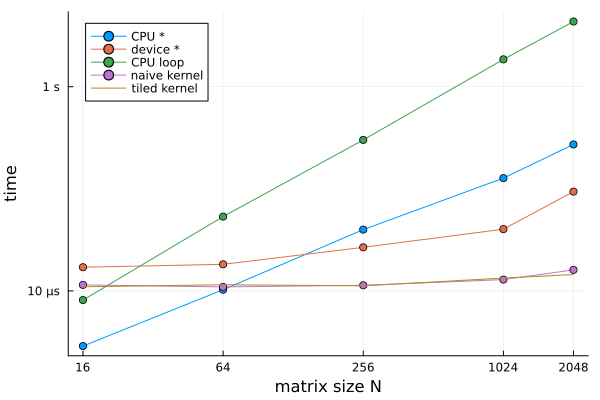

In [33]:
t_dev_tiled = Float64[]
for n in sizes
    X, Y = rand(Float32, n, n), rand(Float32, n, n)
    DX = copyto!(allocate(Backend, Float32, n, n), X)
    DY = copyto!(allocate(Backend, Float32, n, n), Y)
    DZ = KernelAbstractions.zeros(Backend, Float32, n, n)
    k! = tiled_matmul_kernel!(Backend, (TILE_DIM, TILE_DIM))
    push!(t_dev_tiled, @belapsed begin
        $k!($DZ, $DX, $DY; ndrange = ($n, $n))
        KernelAbstractions.synchronize($Backend)
    end)
end

Plots.plot!(plt_matmul, sizes, t_dev_tiled; label = "tiled kernel")
plt_matmul

<div style="border-left: 4px solid #868e96; background: rgba(134, 142, 150, 0.08); padding: 0.4em 1.2em 0.6em; border-radius: 0 6px 6px 0; margin: 1em 0;">

**Question (2.4.3).** Section 2.2.4 plots CPU and device `*`, the CPU triple loop, the naive matmul kernel, and (after the cell above) your tiled matmul kernel.

1. In the naive kernel, each work item computes one entry of `C` but loads a full row of `A` and a full column of `B` from global memory. Why is global bandwidth often the limit, and why do neighboring work items repeat much of the same traffic?
2. Inside the loop over tile index `t`, why do you need `@synchronize()` after loading `tileA` and `tileB`, and again before the next load step? What goes wrong if a work item reads shared memory while a neighbor is still writing it?
3. For small `N`, why can the naive and tiled device kernels sit on a similar time floor? As `N` grows, why does tiling pull ahead of the naive kernel, and why does `DA * DB` (the vendor library) usually stay faster than both custom kernels?

</div>

# 3. Summary

- Naive kernels with one work item per output element: transpose and matrix multiplication
- Global memory access: coalescing and data reuse
- Shared memory (`@localmem`), and a `@synchronize` so that a write and a later read do not overlap
- Tiled kernels: a coalesced transpose, and a matrix multiplication that reuses its tiles

## 3.1. Further exploration

These are optional and not graded.

1. **Bank conflicts and padding.** `transpose_tiled_kernel!` already pads the tile to `(N + 1, N)` for the transposed shared-memory read. Drop the `+ 1`, compare timings, and relate the difference to bank conflicts.
2. **Tile size.** Compare `TILE_DIM` = 8, 16, and 32, and explain the result in terms of occupancy and shared-memory use.
3. **Register blocking.** Let each work item compute a small block of `C` (for example 4×1 or 4×4 elements), keeping partial sums and reused values of `A` and `B` in registers. Too many registers per work item lowers occupancy.
4. **Vendor libraries.** Compare your fastest kernel with `DA * DB` (cuBLAS, rocBLAS, or Metal Performance Shaders). Read the performance guide for your backend (for example the CUDA C++ Best Practices Guide) and identify which recommendations your kernel does not yet follow.

Time a variant the same way: push the times into an array and add a curve with `Plots.plot!(plt_matmul, ...)`.